# A Taste of Deep Learning: CNNs, RNNs, Transformers and Beyond

In the previous notebook we built the plain, fully connected neural network, the multilayer perceptron (MLP). The MLP is the "framework" of deep learning: almost every modern architecture is still made of weights, biases and activation functions, trained by backpropagation and gradient descent.

What changes from one architecture to the next is **how the neurons are wired**, and the wiring is chosen to match the **structure of the data**. This notebook is a short tour to whet your appetite.

:::{admonition} A preview, not a lesson
:class: note
Nothing in this notebook is examinable in detail. The aim is that you recognise these names, know roughly what each one is for, and see why materials scientists care. Each architecture deserves (and will get) a proper treatment in a later course.
:::

:::{admonition} What you will be able to do after this notebook
:class: tip
- Explain why the right architecture depends on the structure of the data (images, sequences, sets, graphs).
- Describe what a **convolution** and a **pooling** step do, and carry one out by hand.
- Explain the **vanishing gradient** problem in recurrent networks in one sentence.
- Describe, in words, what **attention** lets a transformer do.
- Name a materials-science example for CNNs, transformers, graph networks and generative models.
:::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'png'

# Shared look for every figure in this notebook
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#dddcd7"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
    "lines.linewidth": 2, "font.size": 10,
})

## 1. Why not use an MLP for everything?

An MLP needs a flat list of numbers as input. To feed it a grey-scale image, we would **flatten** the image: take the rows of pixels one after another and join them into one long vector. A 28 × 28 image becomes 784 inputs.

Flattening throws away something important: **which pixels are next to each other**. Look at what happens to two pixels that sit directly on top of one another in a small patch of a micrograph:

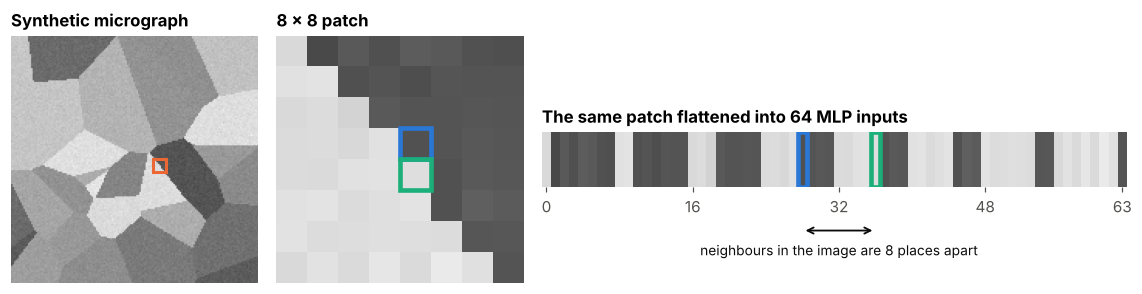

In [2]:
from scipy.spatial import cKDTree

# A synthetic grain microstructure (illustrative only): Voronoi grains with random grey levels
rng = np.random.default_rng(0)
N = 160
seeds = rng.uniform(0, N, size=(28, 2))
yy, xx = np.mgrid[0:N, 0:N]
_, grain_id = cKDTree(seeds).query(np.column_stack([yy.ravel(), xx.ravel()]))
grain_id = grain_id.reshape(N, N)
grey = rng.uniform(0.3, 0.9, size=len(seeds))
micrograph = grey[grain_id] + rng.normal(0, 0.02, size=(N, N))

# Choose an 8x8 patch that contains a clear boundary between two grains
best_score, r0, c0 = -1, 0, 0
for r in range(0, N - 8, 4):
    for c in range(0, N - 8, 4):
        ids = np.unique(grain_id[r:r + 8, c:c + 8])
        frac = np.mean(grain_id[r:r + 8, c:c + 8] == ids[0])
        if len(ids) == 2 and 0.35 <= frac <= 0.65:          # a boundary through the middle
            score = abs(grey[ids[0]] - grey[ids[1]])
            if score > best_score:
                best_score, r0, c0 = score, r, c
patch = micrograph[r0:r0 + 8, c0:c0 + 8]
pa, pb = (3, 4), (4, 4)                       # two vertically adjacent pixels
ia, ib = pa[0] * 8 + pa[1], pb[0] * 8 + pb[1]  # their positions after flattening

fig = plt.figure(figsize=(10.5, 3.3))
gs = fig.add_gridspec(2, 3, width_ratios=[1.1, 1.1, 2.6], height_ratios=[1, 1])
ax0 = fig.add_subplot(gs[:, 0]); ax1 = fig.add_subplot(gs[:, 1]); ax2 = fig.add_subplot(gs[0:2, 2])
ax0.imshow(micrograph, cmap="gray", vmin=0, vmax=1)
ax0.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), 8, 8, fill=False, ec=ORANGE, lw=2))
ax0.set_title("Synthetic micrograph", loc="left"); ax0.set_axis_off()
ax1.imshow(patch, cmap="gray", vmin=0, vmax=1)
for (r, c), col in [(pa, BLUE), (pb, AQUA)]:
    ax1.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, ec=col, lw=3))
ax1.set_title("8 × 8 patch", loc="left"); ax1.set_axis_off()
ax2.imshow(patch.reshape(1, -1), cmap="gray", vmin=0, vmax=1, aspect=6)
for i, col in [(ia, BLUE), (ib, AQUA)]:
    ax2.add_patch(plt.Rectangle((i - 0.5, -0.5), 1, 1, fill=False, ec=col, lw=3))
ax2.annotate("", xy=(ib, 1.3), xytext=(ia, 1.3), arrowprops=dict(arrowstyle="<->", color=INK, lw=1.2),
             annotation_clip=False)
ax2.text((ia + ib) / 2, 1.75, f"neighbours in the image are {ib - ia} places apart", ha="center",
         fontsize=9, color=INK)
ax2.set_yticks([]); ax2.set_xticks([0, 16, 32, 48, 63]); ax2.grid(False)
ax2.set_title("The same patch flattened into 64 MLP inputs", loc="left")
for sp in ax2.spines.values(): sp.set_visible(False)
plt.tight_layout(); plt.show()

In the picture the two highlighted pixels touch. In the flattened list they are 8 places apart, and an MLP treats input 28 and input 36 as no more related than input 28 and input 63. The network would have to *re-learn* the idea of "neighbourhood" from data, separately for every position in the image. That wastes data and knobs.

The fix is to build our knowledge of the data's structure into the wiring. This idea has a name: **inductive bias**.

| Data | Structure that matters | Architecture designed for it |
|---|---|---|
| Images, micrographs, diffraction patterns | Nearby pixels belong together; a feature can appear anywhere | **Convolutional neural network (CNN)** |
| Text, time series, spectra | Order matters | **Recurrent neural network (RNN)**, **transformer** |
| Chemical formulas | A set of elements with fractions; context matters | **Transformer** / attention-based networks |
| Crystal structures, molecules | Atoms connected by bonds or neighbour relations | **Graph neural network (GNN)** |

## 2. Convolutional neural networks (CNNs)

### The convolution step: a small sliding window

A **kernel** (or **filter**) is a small grid of numbers, often 3 × 3. We slide it across the image. At each position we multiply the kernel's numbers by the pixel values underneath, add everything up, and write the result into a new grid called a **feature map**.

A famous hand-designed kernel is the **Sobel filter**. It responds strongly where brightness changes from left to right, in other words at vertical edges. Let us apply it by hand to a tiny image made of three vertical stripes.

In [3]:
import numpy as np

# A tiny 'image': three vertical stripes of brightness 20, 60 and 10
image = np.array([[20, 20, 20, 60, 60, 10]] * 4)

# Sobel kernel: responds to left-to-right changes in brightness (vertical edges)
kernel = np.array([[-1, 0, 1],
                   [-2, 0, 2],
                   [-1, 0, 1]])

# --- Convolution: slide the 3x3 kernel over every position where it fits ---
k = kernel.shape[0]
out_rows = image.shape[0] - k + 1          # 4 - 3 + 1 = 2
out_cols = image.shape[1] - k + 1          # 6 - 3 + 1 = 4
feature_map = np.zeros((out_rows, out_cols), dtype=int)
for i in range(out_rows):
    for j in range(out_cols):
        window = image[i:i + k, j:j + k]               # the 3x3 patch under the kernel
        feature_map[i, j] = np.sum(window * kernel)    # multiply element-wise, then add

# --- Pooling: shrink the feature map by summarising each 2x2 block ---
def pool(fmap, size=2, how=np.max):
    r, c = fmap.shape[0] // size, fmap.shape[1] // size
    return np.array([[how(fmap[i*size:(i+1)*size, j*size:(j+1)*size]) for j in range(c)]
                     for i in range(r)])

print("Input image (4 x 6):\n", image)
print("\nFeature map after convolution (2 x 4):\n", feature_map)
print("\nMax pooling, 2x2 blocks (1 x 2):    ", pool(feature_map, how=np.max))
print("Average pooling, 2x2 blocks (1 x 2):", pool(feature_map, how=np.mean))

Input image (4 x 6):
 [[20 20 20 60 60 10]
 [20 20 20 60 60 10]
 [20 20 20 60 60 10]
 [20 20 20 60 60 10]]

Feature map after convolution (2 x 4):
 [[   0  160  160 -200]
 [   0  160  160 -200]]

Max pooling, 2x2 blocks (1 x 2):     [[160 160]]
Average pooling, 2x2 blocks (1 x 2): [[ 80. -20.]]


Read the feature map from left to right:

- **0** where the window sits inside the uniform stripe of 20s: no edge, no response.
- **+160** where the window straddles the jump from 20 to 60: a dark-to-bright edge.
- **−200** where it straddles the drop from 60 to 10: a bright-to-dark edge. The sign tells us the direction, and the size tells us how strong the edge is.

Notice that the feature map is **smaller** than the image. A 3 × 3 kernel only fits in $(4-3+1) \times (6-3+1) = 2 \times 4$ positions. (Real CNNs often add a border of zeros, called **padding**, to keep the size unchanged.)

:::{note}
Strictly speaking, what CNNs compute is a *cross-correlation*: the kernel is not flipped as in the textbook definition of convolution. Everyone still calls it convolution, and because the kernel values are learned, the difference does not matter in practice.
:::

### The pooling step: keep the important part, shrink the rest

**Pooling** summarises each small block of a feature map with a single number. **Max pooling** keeps the largest value, a bit like asking "was this feature present anywhere in this block?". **Average pooling** keeps the mean. Pooling shrinks the data (less computation, fewer knobs later on), keeps the strongest signals, and helps reduce overfitting. In the example, max pooling kept the strong edge responses (160, 160), while average pooling diluted them with the zeros and partly cancelled the opposite-signed edges (80, −20).

### Kernels on a real-looking image

Here is the same idea on our synthetic micrograph. A Sobel kernel and its 90°-rotated partner pick out boundaries running in different directions:

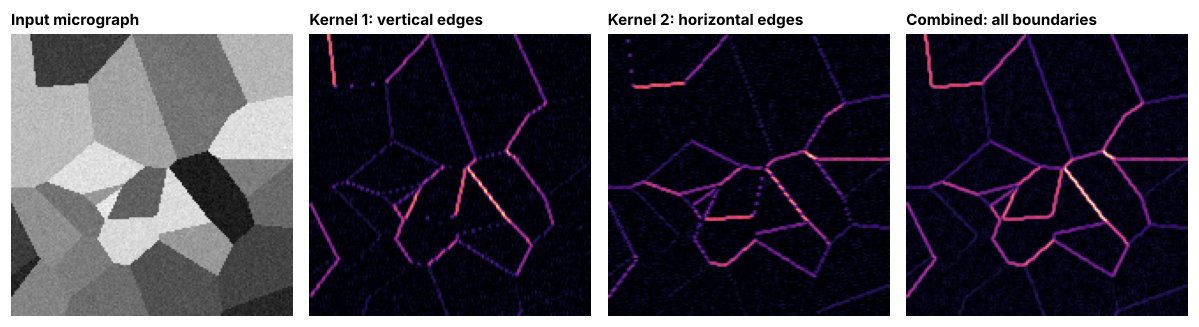

In [4]:
from scipy.ndimage import correlate

sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)
sobel_y = sobel_x.T
gx = correlate(micrograph, sobel_x, mode="nearest")
gy = correlate(micrograph, sobel_y, mode="nearest")
mag = np.hypot(gx, gy)

fig, axes = plt.subplots(1, 4, figsize=(11, 3.0))
panels = [(micrograph, "Input micrograph"), (np.abs(gx), "Kernel 1: vertical edges"),
          (np.abs(gy), "Kernel 2: horizontal edges"), (mag, "Combined: all boundaries")]
for ax, (img, title) in zip(axes, panels):
    ax.imshow(img, cmap="gray" if img is micrograph else "magma")
    ax.set_title(title, loc="left", fontsize=10); ax.set_axis_off()
plt.tight_layout(); plt.show()

Each kernel produces its own feature map. A CNN uses many kernels at once (each producing one **channel**), so one layer can look for vertical edges, horizontal edges, corners, textures and more, all in parallel.

### The key idea: the kernel values are learned

Here we *chose* the Sobel numbers. In a CNN, the numbers inside each kernel are **weights**, initialised randomly and tuned by backpropagation, exactly like the weights in the previous notebook. The network discovers for itself which local patterns are useful. Because the same small kernel is reused at every position (**weight sharing**), a CNN needs far fewer knobs than an MLP looking at the same image, and it can spot a feature wherever it appears.

### Putting a CNN together

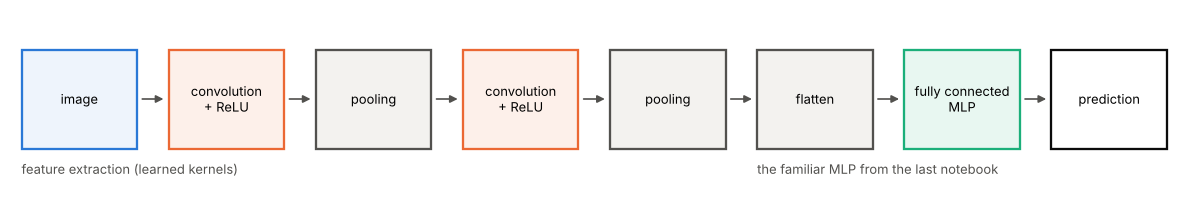

In [5]:
blocks = [("image", "#eef4fc", BLUE), ("convolution\n+ ReLU", "#fdf0ea", ORANGE), ("pooling", "#f3f2ef", MUTED),
          ("convolution\n+ ReLU", "#fdf0ea", ORANGE), ("pooling", "#f3f2ef", MUTED),
          ("flatten", "#f3f2ef", MUTED), ("fully connected\nMLP", "#e8f7f1", AQUA), ("prediction", "white", INK)]
fig, ax = plt.subplots(figsize=(11, 1.9))
ax.set_axis_off(); ax.set_xlim(0, len(blocks) * 1.4); ax.set_ylim(0, 1.6)
for i, (label, fc, ec) in enumerate(blocks):
    x = i * 1.4 + 0.1
    ax.add_patch(plt.Rectangle((x, 0.35), 1.1, 0.9, fc=fc, ec=ec, lw=1.5))
    ax.text(x + 0.55, 0.8, label, ha="center", va="center", fontsize=8.5)
    if i < len(blocks) - 1:
        ax.annotate("", xy=(x + 1.38, 0.8), xytext=(x + 1.12, 0.8),
                    arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.1))
ax.text(0.1, 0.12, "feature extraction (learned kernels)", color=MUTED, fontsize=8.5)
ax.text(5 * 1.4 + 0.1, 0.12, "the familiar MLP from the last notebook", color=MUTED, fontsize=8.5)
plt.tight_layout(); plt.show()

A typical CNN stacks several **convolution → activation (ReLU) → pooling** blocks. Early layers learn simple features such as edges; deeper layers combine them into larger patterns such as grain shapes, particles or defects. The final feature maps are **flattened** and passed to an ordinary fully connected network that makes the prediction. Training follows the same loop as before: random starting kernels, forward pass, cost, backpropagation, update. The number of kernels, their size and the number of layers are **hyperparameters**, chosen by validation.

:::{admonition} CNNs in materials science
:class: tip
Image analysis is everywhere in materials work: optical and electron micrographs, diffraction patterns, tomography. CNNs are used to denoise, segment and classify such images. For example, Giannatou *et al.* (2019) trained a CNN to remove noise from SEM images of lithographic lines so that line-edge roughness could be measured more reliably, and Pelt and Sethian (2018) introduced a CNN design, the mixed-scale dense network, for segmenting and denoising scientific images. Automated image analysis is also a key ingredient of **self-driving laboratories**.
:::

## 3. Sequences: recurrent neural networks (RNNs)

Text, time series and spectra are **sequences**: the order matters. A **recurrent neural network** reads a sequence one step at a time. At each step it combines the new input $x_t$ with a **hidden state** $h_{t-1}$ carried over from the previous step, a kind of running memory:

$$
h_t = \sigma\left(W_x\,x_t + W_h\,h_{t-1} + b\right)
$$

The **same** weights $W_x$, $W_h$ and $b$ are used at every step, which is another form of weight sharing. Drawn "unrolled" in time, an RNN looks like a chain of identical networks, each passing a message to the next.

### The vanishing gradient problem

To train an RNN, backpropagation has to pass error signals back through **every step of the chain**. From the previous notebook, each step back multiplies the signal by an activation slope (and a weight). The slope of the sigmoid is never larger than 0.25. Multiply many numbers smaller than 1 together and the result shrinks towards zero very fast:

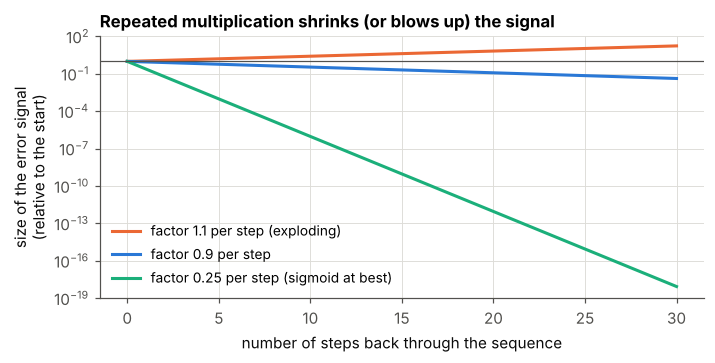

After 10 steps: 0.25^10 = 9.5e-07,  0.9^10 = 0.35,  1.1^10 = 2.59


In [6]:
steps = np.arange(0, 31)
fig, ax = plt.subplots(figsize=(6.6, 3.4))
ax.plot(steps, 1.1 ** steps, color=ORANGE, label="factor 1.1 per step (exploding)")
ax.plot(steps, 0.9 ** steps, color=BLUE, label="factor 0.9 per step")
ax.plot(steps, 0.25 ** steps, color=AQUA, label="factor 0.25 per step (sigmoid at best)")
ax.axhline(1, color=MUTED, lw=0.8)
ax.set_yscale("log"); ax.set_ylim(1e-19, 1e2)
ax.set_xlabel("number of steps back through the sequence")
ax.set_ylabel("size of the error signal\n(relative to the start)")
ax.set_title("Repeated multiplication shrinks (or blows up) the signal", loc="left")
ax.legend(fontsize=9, loc="lower left")
plt.tight_layout(); plt.show()
print(f"After 10 steps: 0.25^10 = {0.25**10:.1e},  0.9^10 = {0.9**10:.2f},  1.1^10 = {1.1**10:.2f}")

After only ten steps at the sigmoid's best-case slope, the error signal is about a millionth of its starting size. The weights that link early words to the final output barely get updated, so the network effectively **forgets the beginning of long sequences** (Bengio, Simard and Frasconi, 1994). If the factor is larger than 1, the opposite happens and gradients **explode**.

Consider: *"The pizza came out of the oven, and it looked delicious."* To know that "it" means the pizza, a model must connect words that are far apart. Variants called **LSTM** (long short-term memory; Hochreiter and Schmidhuber, 1997) and **GRU** (gated recurrent unit; Cho *et al.*, 2014) add "gates" that let information skip along the chain more easily. They helped a great deal, but they still read one step at a time, which is slow to train on long sequences.

## 4. Words as vectors: embeddings

Before a network can work with words (or chemical elements), each one must become a list of numbers. An **embedding** represents each word as a dense vector of real numbers, learned so that words used in similar ways end up with similar vectors. Classic methods such as **Word2Vec** (Mikolov *et al.*, 2013) learn one fixed vector per word from how words co-occur in large amounts of text.

:::{admonition} Embeddings in materials science
:class: tip
Tshitoyan *et al.* (2019) trained Word2Vec-style embeddings ("mat2vec") on about 3.3 million materials-science abstracts published between 1922 and 2018. Without being told any chemistry, the vectors captured relationships such as the layout of the periodic table, and the authors showed that they could help identify candidate thermoelectric materials years before those materials were reported as thermoelectrics.
:::

A fixed vector per word has a weakness: one word can mean different things.

- *The metal* **conducts** *electricity.*
- *The maestro* **conducts** *the orchestra.*

We would like the vector for "conducts" to depend on its **context**. That is exactly what attention provides.

## 5. Attention and transformers

In 2017, Vaswani *et al.* proposed the **transformer**, an architecture built entirely from attention, with no recurrence and no convolutions. Their paper's title, *Attention Is All You Need*, has become famous. Transformers now power large language models such as BERT and GPT, and many scientific models.

### What does attention do?

Instead of reading one word at a time, **self-attention** lets every word look at every other word in the sentence **at the same time** and decide how much each one matters to it. Each word's new representation is then a **weighted average** of all the words, with weights set by relevance.

Here is a toy version you can follow by hand. We give each word a hand-made 4-number vector with the meaning `[materials, music, action, filler]`, and compute attention weights as the softmax of scaled dot products (dot product = "how similar are these two vectors?").

:::{note}
This is a **toy**: the vectors are invented for illustration, and a real transformer *learns* separate "query", "key" and "value" transformations rather than using the raw vectors. But the arithmetic of the weighted average is the same.
:::

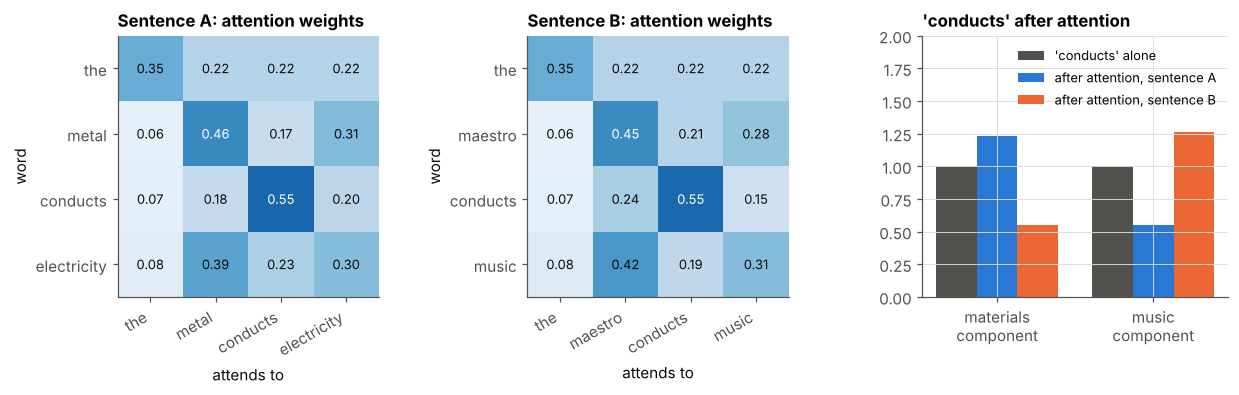

'conducts' after attention  A: [1.23 0.55 0.91 0.07]   B: [0.55 1.26 0.92 0.07]


In [7]:
vocab = {                       # [materials, music, action, filler]  (hand-made toy vectors)
    "the":         [0.0, 0.0, 0.0, 1.0],
    "metal":       [2.0, 0.0, 0.0, 0.0],
    "electricity": [1.6, 0.0, 0.4, 0.0],
    "maestro":     [0.0, 2.0, 0.4, 0.0],
    "music":       [0.0, 1.6, 0.0, 0.0],
    "conducts":    [1.0, 1.0, 1.5, 0.0],   # ambiguous on its own
}

def self_attention(words):
    E = np.array([vocab[w] for w in words])
    scores = E @ E.T / np.sqrt(E.shape[1])            # similarity of every pair of words
    weights = np.exp(scores) / np.exp(scores).sum(axis=1, keepdims=True)   # softmax, rows sum to 1
    return weights, weights @ E                       # new vectors = weighted averages

sentA = ["the", "metal", "conducts", "electricity"]
sentB = ["the", "maestro", "conducts", "music"]
WA, outA = self_attention(sentA)
WB, outB = self_attention(sentB)

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [1, 1, 1.05]})
for ax, W, sent, title in [(axes[0], WA, sentA, "Sentence A"), (axes[1], WB, sentB, "Sentence B")]:
    ax.imshow(W, cmap="Blues", vmin=0, vmax=0.7)
    ax.set_xticks(range(4)); ax.set_xticklabels(sent, rotation=30, ha="right")
    ax.set_yticks(range(4)); ax.set_yticklabels(sent)
    ax.grid(False)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{W[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                    color="white" if W[i, j] > 0.45 else INK)
    ax.set_title(f"{title}: attention weights", loc="left")
    ax.set_xlabel("attends to"); ax.set_ylabel("word")

ax = axes[2]
labels = ["materials", "music"]
before = np.array(vocab["conducts"][:2])
xs = np.arange(2); wbar = 0.26
ax.bar(xs - wbar, before, wbar, color=MUTED, label="'conducts' alone")
ax.bar(xs, outA[2, :2], wbar, color=BLUE, label="after attention, sentence A")
ax.bar(xs + wbar, outB[2, :2], wbar, color=ORANGE, label="after attention, sentence B")
ax.set_xticks(xs); ax.set_xticklabels([f"{l}\ncomponent" for l in labels])
ax.set_ylim(0, 2.0)
ax.set_title("'conducts' after attention", loc="left")
ax.legend(fontsize=8.5, loc="upper right")
plt.tight_layout(); plt.show()
print("'conducts' after attention  A:", np.round(outA[2], 2), "  B:", np.round(outB[2], 2))

In sentence A, "conducts" pays attention to "metal" and "electricity", so its new vector leans towards the *materials* direction. In sentence B the same word leans towards *music*. **The same word gets a different representation in different contexts.** Such context-dependent vectors are called **contextual embeddings**.

Two more ingredients make a full transformer:

- **Positional encoding.** Attention looks at all words at once, so on its own it has no idea of word order. A position-dependent vector is added to each word's embedding so that order information is not lost.
- **Many heads and many layers.** A transformer runs several attention calculations in parallel (**multi-head attention**), each free to learn a different kind of relationship, and stacks many such layers with small MLPs in between.

Because all words are processed at the same time rather than one by one, transformers train efficiently on modern hardware, and long-range connections no longer have to survive a long chain of multiplications.

### Attention for materials: elements as "words"

A chemical formula can be treated like a short sentence whose "words" are elements, each with a fraction. Earlier in the course you built **composition-based feature vectors (CBFVs)**: a fixed recipe that averages element properties, weighted by fraction. A known limitation is that an element contributes the same way whatever its partners are.

- **CrabNet** (Wang, Kauwe, Murdock and Sparks, 2021) applies transformer self-attention to compositions, so each element's representation is updated according to the other elements in the compound. It matched or exceeded strong baselines on most of 28 benchmark datasets. The authors visualised attention for Al₂O₃ in a model trained on bulk modulus; in one attention head, Al and O attend strongly to each other.
- **Roost** (Goodall and Lee, 2020) treats the formula as a **dense weighted graph** between elements and passes messages between them using an attention mechanism, learning its own descriptors from stoichiometry alone, without needing the crystal structure.

:::{admonition} Be careful with "the model is paying attention to…"
:class: important
Attention maps are tempting to read as explanations, and sometimes they line up nicely with chemical intuition. But high attention weight does not by itself prove that the model *relies* on that relationship for its prediction. This has been debated directly in the machine-learning literature (Jain and Wallace, 2019). Treat attention maps as a hypothesis worth testing, not as proof.
:::

## 6. The wider zoo

A few more families you will meet. Each is still weights, biases, activations and backpropagation underneath.

| Architecture | Built for | What it does, in a sentence | Materials example |
|---|---|---|---|
| **Graph neural network (GNN)** | Crystals, molecules | Atoms are nodes, bonds or neighbours are edges; atoms repeatedly exchange "messages" with neighbours | CGCNN predicts properties directly from crystal graphs (Xie and Grossman, 2018); GNoME used GNNs to screen millions of candidate crystals (Merchant *et al.*, 2023) |
| **Generative adversarial network (GAN)** | Generating new samples | A generator tries to fool a discriminator; both improve together (Goodfellow *et al.*, 2014) | Generating realistic synthetic microstructure images |
| **Variational autoencoder (VAE)** | Compression and generation | Squeezes data into a small "latent space" and learns to rebuild it; new samples come from the latent space (Kingma and Welling, 2014) | Smooth latent spaces of structures or compositions to explore |
| **Diffusion model** | Generating new samples | Learns to remove noise step by step, so it can turn pure noise into a realistic sample (Ho, Jain and Abbeel, 2020) | MatterGen generates new stable inorganic crystal structures with target properties (Zeni *et al.*, 2025) |

Generative models open the door to **inverse design**: instead of asking "what is the property of this material?", we ask "which material would have this property?".

:::{admonition} Keep the classical toolbox close
:class: tip
Everything in the previous notebook's "limitations" section applies with extra force here: these models are data-hungry, expensive to train, and hard to interpret. For a few hundred rows of tabular data, the classical methods from this course are usually the right first choice. Deep architectures shine when the data are large or have rich structure (images, text, graphs).
:::

## Where next?

This tour skipped almost all the details: padding and strides, gated cells, query/key/value matrices, message passing, training tricks such as dropout and batch normalisation, and the practical side of training on GPUs with libraries like PyTorch. Those are the subject of a later course. For now, the main message is this:

> **Choose the wiring to match the structure of your data, and keep everything you learned about validation, scaling, regularisation and honest evaluation.** None of that changes.

## Words to listen for

| Term | Meaning in one line |
|---|---|
| **Inductive bias** | Assumptions about the data built into a model's design |
| **Convolutional neural network (CNN)** | A network that slides small learned kernels across grid-like data such as images |
| **Kernel (filter)** | A small grid of learnable weights applied at every position of an image |
| **Feature map / channel** | The output grid produced by one kernel |
| **Padding / stride** | Zeros added around the border / how far the kernel moves each step |
| **Pooling (max / average)** | Shrinking a feature map by summarising small blocks |
| **Weight sharing** | Reusing the same weights at every position (CNNs) or time step (RNNs) |
| **Recurrent neural network (RNN)** | A network that reads a sequence step by step, carrying a hidden state |
| **Vanishing / exploding gradient** | Error signals shrinking to zero (or blowing up) as they pass back through many steps |
| **LSTM / GRU** | RNN variants with gates that help remember over longer sequences |
| **Embedding** | A learned vector of numbers that represents a word, element or other item |
| **Self-attention** | Each item updates itself using a relevance-weighted average of all items |
| **Transformer** | An architecture built from stacked attention layers and small MLPs |
| **Positional encoding** | Information about order added to each item's embedding |
| **Graph neural network (GNN)** | A network that passes messages between connected nodes, such as atoms |
| **GAN / VAE / diffusion model** | Families of generative models that create new samples |
| **Inverse design** | Searching for materials that have a target property |

## Check your understanding

**1.** In your own words, why does flattening an image before feeding it to an MLP throw away useful information?

:::{dropdown} Answer (instructor solution: remove before distribution)
Flattening puts pixels that are neighbours in the image (for example, one directly above another) far apart in the input list. The MLP has no built-in notion that they are related, so it must learn spatial relationships from data, separately for each position. CNNs build "nearby pixels belong together" into their design.
:::

**2.** A 3 × 3 kernel slides over a 10 × 10 image with a step (stride) of 1 and no padding. What is the size of the feature map? What is the size after 2 × 2 max pooling with stride 2?

:::{dropdown} Answer (instructor solution: remove before distribution)
Feature map: $(10 - 3 + 1) \times (10 - 3 + 1) = 8 \times 8$. After 2 × 2 max pooling: $4 \times 4$.
:::

**3.** In the Sobel example, why did one edge give +160 and the other −200?

:::{dropdown} Answer (instructor solution: remove before distribution)
The kernel's left column is negative and its right column positive, so it measures (brightness on the right) − (brightness on the left), weighted 1, 2, 1 down the column (total weight 4). The 20 → 60 jump gives $4 \times 40 = +160$; the 60 → 10 drop gives $4 \times (-50) = -200$. The sign gives the direction of the change and the size its strength.
:::

**4.** Why do simple RNNs struggle to link words that are far apart in a long sentence?

:::{dropdown} Answer (instructor solution: remove before distribution)
During backpropagation the error signal is multiplied by a factor at every step back through the sequence. When those factors are smaller than 1 (as for the sigmoid, whose slope is at most 0.25), the signal shrinks towards zero: the vanishing gradient problem. Early words then have almost no influence on learning.
:::

**5.** What can CrabNet's attention do that a composition-based feature vector (CBFV) cannot?

:::{dropdown} Answer (instructor solution: remove before distribution)
A CBFV combines element properties with a fixed, fraction-weighted recipe, so each element contributes the same way regardless of its partners. Attention lets each element's representation change depending on the other elements present, and the network learns this from data instead of following a fixed recipe.
:::

## References

- Bengio, Y., Simard, P. and Frasconi, P. (1994). Learning long-term dependencies with gradient descent is difficult. *IEEE Transactions on Neural Networks*, 5(2), 157–166.
- Cho, K. *et al.* (2014). Learning phrase representations using RNN encoder–decoder for statistical machine translation. *Proceedings of EMNLP 2014*.
- Giannatou, E., Papavieros, G., Constantoudis, V., Papageorgiou, H. and Gogolides, E. (2019). Deep learning denoising of SEM images towards noise-reduced LER measurements. *Microelectronic Engineering*, 216.
- Goodall, R. E. A. and Lee, A. A. (2020). Predicting materials properties without crystal structure: deep representation learning from stoichiometry. *Nature Communications*, 11, 6280.
- Goodfellow, I. *et al.* (2014). Generative adversarial nets. *Advances in Neural Information Processing Systems 27*.
- Ho, J., Jain, A. and Abbeel, P. (2020). Denoising diffusion probabilistic models. *Advances in Neural Information Processing Systems 33*.
- Hochreiter, S. and Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*, 9(8), 1735–1780.
- Jain, S. and Wallace, B. C. (2019). Attention is not explanation. *Proceedings of NAACL-HLT 2019*.
- Kingma, D. P. and Welling, M. (2014). Auto-encoding variational Bayes. *International Conference on Learning Representations (ICLR)*. arXiv:1312.6114.
- Merchant, A. *et al.* (2023). Scaling deep learning for materials discovery. *Nature*, 624, 80–85.
- Mikolov, T., Chen, K., Corrado, G. and Dean, J. (2013). Efficient estimation of word representations in vector space. arXiv:1301.3781.
- Pelt, D. M. and Sethian, J. A. (2018). A mixed-scale dense convolutional neural network for image analysis. *Proceedings of the National Academy of Sciences*, 115(2), 254–259.
- Tshitoyan, V. *et al.* (2019). Unsupervised word embeddings capture latent knowledge from materials science literature. *Nature*, 571, 95–98.
- Vaswani, A. *et al.* (2017). Attention is all you need. *Advances in Neural Information Processing Systems 30*. arXiv:1706.03762.
- Wang, A. Y.-T., Kauwe, S. K., Murdock, R. J. and Sparks, T. D. (2021). Compositionally restricted attention-based network for materials property predictions. *npj Computational Materials*, 7, 77.
- Xie, T. and Grossman, J. C. (2018). Crystal graph convolutional neural networks for an accurate and interpretable prediction of material properties. *Physical Review Letters*, 120, 145301.
- Zeni, C. *et al.* (2025). A generative model for inorganic materials design. *Nature*, 639. DOI 10.1038/s41586-025-08628-5